In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Try environment variable, then Data/USDA, then local fallback
USDA_PATH = os.environ.get(
    "USDA_DATA_DIR",
    os.path.abspath(os.path.join(os.getcwd(), "Data/USDA"))
    if os.path.exists(os.path.abspath(os.path.join(os.getcwd(), "Data/USDA/food.csv")))
    else os.path.abspath(os.path.join(os.getcwd(), "../Data/USDA"))
    if os.path.exists(os.path.abspath(os.path.join(os.getcwd(), "../Data/USDA/food.csv")))
    else "."
)

print("Using USDA_PATH:", USDA_PATH)
print("USDA files available:")
for file in os.listdir(USDA_PATH):
    print("-", file)


Using USDA_PATH: /Users/diwashbaral/AI/ai_code/Savora-AI-Meal-Planner-GC-1/Data/USDA
USDA files available:
- food_calorie_conversion_factor.csv
- food_nutrient_conversion_factor.csv
- food_attribute_type.csv
- foundation_food.csv
- measure_unit.csv
- nutrient.csv
- food.csv
- food_nutrient.csv
- food_protein_conversion_factor.csv
- food_portion.csv
- food_component.csv
- food_category.csv


In [3]:
file_info = []

for file in os.listdir(USDA_PATH):
    file_path = os.path.join(USDA_PATH, file)

    if os.path.isfile(file_path):
        size_mb = os.path.getsize(file_path) / (1024**2)

        file_info.append({"file": file, "size_MB": round(size_mb, 2)})

file_info_df = (
    pd.DataFrame(file_info).sort_values("size_MB", ascending=False).reset_index(drop=True)
)

display(file_info_df)

,file,size_MB
0,food_nutrient.csv,1687.10
1,food.csv,205.51
2,food_portion.csv,3.21
3,food_nutrient_conversion_factor.csv,0.19
4,food_component.csv,0.17
5,foundation_food.csv,0.02
6,nutrient.csv,0.02
7,food_calorie_conversion_factor.csv,0.01
8,food_protein_conversion_factor.csv,0.01
9,food_attribute_type.csv,0.00


In [4]:
food = pd.read_csv(os.path.join(USDA_PATH, "food.csv"))

print("Shape:", food.shape)
print("\nColumns:")
print(food.columns.tolist())

Shape: (2063876, 5)

Columns:
['fdc_id', 'data_type', 'description', 'food_category_id', 'publication_date']


In [5]:
display(food.head())

,fdc_id,data_type,description,food_category_id,publication_date
0,1105904,branded_food,WESSON Vegetable Oil 1 GAL,Oils Edible,2020-11-13
1,1105905,branded_food,SWANSON BROTH BEEF,Herbs/Spices/Extracts,2020-11-13
2,1105906,branded_food,CAMPBELL'S SLOW KETTLE SOUP CLAM CHOWDER,Prepared Soups,2020-11-13
3,1105907,branded_food,CAMPBELL'S SLOW KETTLE SOUP CHEESE BROCCOLI,Prepared Soups,2020-11-13
4,1105898,experimental_food,Discrepancy between the Atwater factor predicted and empirically measured energy values of almon...,NaN,2020-10-30


In [6]:
food.info()

<class 'pandas.DataFrame'>
RangeIndex: 2063876 entries, 0 to 2063875
Data columns (total 5 columns):
 #   Column            Dtype
---  ------            -----
 0   fdc_id            int64
 1   data_type         str  
 2   description       str  
 3   food_category_id  str  
 4   publication_date  str  
dtypes: int64(1), str(4)
memory usage: 78.7 MB


In [7]:
food_missing = pd.DataFrame(
    {"missing_count": food.isnull().sum(), "missing_percentage": food.isnull().mean() * 100}
).sort_values("missing_percentage", ascending=False)

display(food_missing)

,missing_count,missing_percentage
food_category_id,12673,0.614039
description,9,0.000436
fdc_id,0,0.000000
data_type,0,0.000000
publication_date,0,0.000000


In [8]:
print("Duplicate rows:", food.duplicated().sum())

Duplicate rows: 0


In [9]:
id_columns = [col for col in food.columns if "id" in col.lower()]

print("Potential ID columns:")
print(id_columns)

Potential ID columns:
['fdc_id', 'food_category_id']


In [10]:
if "fdc_id" in food.columns:
    print("Total food records:", len(food))
    print("Unique FDC IDs:", food["fdc_id"].nunique())
    print("Duplicate FDC IDs:", food["fdc_id"].duplicated().sum())

Total food records: 2063876
Unique FDC IDs: 2063876
Duplicate FDC IDs: 0


In [11]:
if "description" in food.columns:
    display(food["description"].head(30).to_frame("food_description"))

,food_description
0,WESSON Vegetable Oil 1 GAL
1,SWANSON BROTH BEEF
2,CAMPBELL'S SLOW KETTLE SOUP CLAM CHOWDER
3,CAMPBELL'S SLOW KETTLE SOUP CHEESE BROCCOLI
4,Discrepancy between the Atwater factor predicted and empirically measured energy values of almon...
5,Food processing and structure impact the metabolizable energy of almonds
6,Metabolizable Energy from Cashew Nuts is Less than that Predicted by Atwater Factors
7,Measured energy value of pistachios in the human diet
8,Walnuts Consumed by Healthy Adults Provide Less Available Energy than Predicted by the Atwater F...
9,SWANSON BROTH CHICKEN


In [12]:
if "description" in food.columns:
    food_name_lengths = food["description"].fillna("").astype(str).str.len()

    print(food_name_lengths.describe())

count    2.063876e+06
mean     4.028968e+01
std      2.709593e+01
min      0.000000e+00
25%      2.200000e+01
50%      3.500000e+01
75%      5.000000e+01
max      5.810000e+02
Name: description, dtype: float64


In [13]:
food_category = pd.read_csv(os.path.join(USDA_PATH, "food_category.csv"))

print("Shape:", food_category.shape)
print("\nColumns:")
print(food_category.columns.tolist())

display(food_category.head())

Shape: (28, 3)

Columns:
['id', 'code', 'description']


,id,code,description
0,1,100,Dairy and Egg Products
1,2,200,Spices and Herbs
2,3,300,Baby Foods
3,4,400,Fats and Oils
4,5,500,Poultry Products


In [14]:
food_category.info()

<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           28 non-null     int64
 1   code         28 non-null     int64
 2   description  28 non-null     str  
dtypes: int64(2), str(1)
memory usage: 804.0 bytes


In [15]:
display(
    pd.DataFrame(
        {
            "missing_count": food_category.isnull().sum(),
            "missing_percentage": food_category.isnull().mean() * 100,
        }
    )
)

,missing_count,missing_percentage
id,0,0.0
code,0,0.0
description,0,0.0


In [16]:
nutrient = pd.read_csv(os.path.join(USDA_PATH, "nutrient.csv"))

print("Shape:", nutrient.shape)
print("\nColumns:")
print(nutrient.columns.tolist())

display(nutrient.head())

Shape: (477, 5)

Columns:
['id', 'name', 'unit_name', 'nutrient_nbr', 'rank']


,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
2,1001,Solids,G,201.0,200.0
3,1002,Nitrogen,G,202.0,500.0
4,1003,Protein,G,203.0,600.0


In [17]:
nutrient.info()

<class 'pandas.DataFrame'>
RangeIndex: 477 entries, 0 to 476
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            477 non-null    int64  
 1   name          477 non-null    str    
 2   unit_name     477 non-null    str    
 3   nutrient_nbr  465 non-null    float64
 4   rank          466 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 18.8 KB


In [18]:
display(nutrient.head(50))

,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
2,1001,Solids,G,201.0,200.0
3,1002,Nitrogen,G,202.0,500.0
4,1003,Protein,G,203.0,600.0
5,1004,Total lipid (fat),G,204.0,800.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0,999999.0
8,1007,Ash,G,207.0,1000.0
9,1008,Energy,KCAL,208.0,300.0


In [19]:
[
    col
    for col in nutrient.columns
    if any(word in col.lower() for word in ["name", "nutrient", "unit"])
]

['name', 'unit_name', 'nutrient_nbr']

In [20]:
required_keywords = [
    "energy",
    "protein",
    "carbohydrate",
    "fat",
    "saturated",
    "fiber",
    "sugar",
    "sodium",
]

nutrient_matches = nutrient[
    nutrient["name"].astype(str).str.contains("|".join(required_keywords), case=False, na=False)
]

display(nutrient_matches)

,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
4,1003,Protein,G,203.0,600.0
5,1004,Total lipid (fat),G,204.0,800.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0,999999.0
9,1008,Energy,KCAL,208.0,300.0
50,1049,"Solids, non-fat",G,253.0,999999.0
51,1050,"Carbohydrate, by summation",G,205.2,1120.0
54,1053,Adjusted Protein,G,257.0,700.0


In [21]:
[
    col
    for col in nutrient.columns
    if any(word in col.lower() for word in ["name", "nutrient", "unit"])
]

['name', 'unit_name', 'nutrient_nbr']

In [22]:
print(food.shape)
print(food.columns.tolist())

(2063876, 5)
['fdc_id', 'data_type', 'description', 'food_category_id', 'publication_date']


In [23]:
print(food_category.shape)
print(food_category.columns.tolist())

(28, 3)
['id', 'code', 'description']


In [24]:
print(nutrient.shape)
print(nutrient.columns.tolist())

(477, 5)
['id', 'name', 'unit_name', 'nutrient_nbr', 'rank']


In [25]:
[
    col
    for col in nutrient.columns
    if any(word in col.lower() for word in ["name", "nutrient", "unit"])
]

['name', 'unit_name', 'nutrient_nbr']

In [26]:
required_keywords = [
    "energy",
    "protein",
    "carbohydrate",
    "fat",
    "saturated",
    "fiber",
    "fibre",
    "sugar",
    "sodium",
]

nutrient_matches = nutrient[
    nutrient["name"].astype(str).str.contains("|".join(required_keywords), case=False, na=False)
].copy()

display(nutrient_matches[["id", "name", "unit_name", "nutrient_nbr", "rank"]].sort_values("name"))

,id,name,unit_name,nutrient_nbr,rank
54,1053,Adjusted Protein,G,257.0,700.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
51,1050,"Carbohydrate, by summation",G,205.2,1120.0
73,1072,"Carbohydrate, other",G,284.0,NaN
450,2039,Carbohydrates,G,956.0,1100.0
63,1062,Energy,kJ,268.0,400.0
9,1008,Energy,KCAL,208.0,300.0
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
319,1319,"Fatty acids, monounsat., other",G,678.0,999999.0


In [27]:
target_nutrients = nutrient[
    nutrient["name"]
    .astype(str)
    .str.contains(
        "Energy|Protein|Carbohydrate|Total lipid|Saturated|Fiber|Fibre|Sugars|Sodium",
        case=False,
        na=False,
        regex=True,
    )
].copy()

display(target_nutrients[["id", "name", "unit_name", "nutrient_nbr"]])

,id,name,unit_name,nutrient_nbr
0,2047,Energy (Atwater General Factors),KCAL,957.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0
4,1003,Protein,G,203.0
5,1004,Total lipid (fat),G,204.0
6,1005,"Carbohydrate, by difference",G,205.0
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0
9,1008,Energy,KCAL,208.0
51,1050,"Carbohydrate, by summation",G,205.2
54,1053,Adjusted Protein,G,257.0
63,1062,Energy,kJ,268.0


In [28]:
energy_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("energy", case=False, na=False)
]

display(energy_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
9,1008,Energy,KCAL,208.0,300.0
63,1062,Energy,kJ,268.0,400.0


In [29]:
protein_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("protein", case=False, na=False)
]

display(protein_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
4,1003,Protein,G,203.0,600.0
54,1053,Adjusted Protein,G,257.0,700.0


In [30]:
carb_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("carbohydrate", case=False, na=False)
]

display(carb_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
51,1050,"Carbohydrate, by summation",G,205.2,1120.0
73,1072,"Carbohydrate, other",G,284.0,NaN
450,2039,Carbohydrates,G,956.0,1100.0


In [31]:
fat_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("fat|lipid", case=False, na=False)
]

display(fat_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]].head(50))

,id,name,unit_name,nutrient_nbr,rank
5,1004,Total lipid (fat),G,204.0,800.0
50,1049,"Solids, non-fat",G,253.0,999999.0
86,1085,Total fat (NLEA),G,298.0,900.0
256,1255,Phospholipids,G,603.0,999999.0
257,1256,Glycolipids,G,604.0,999999.0
258,1257,"Fatty acids, total trans",G,605.0,15400.0
259,1258,"Fatty acids, total saturated",G,606.0,9700.0
290,1290,Unsaponifiable matter (lipids),G,643.0,999999.0
291,1291,"Fatty acids, other than 607-615, 617-621, 624-632, 652-654, 686-689)",G,644.0,999999.0
292,1292,"Fatty acids, total monounsaturated",G,645.0,11400.0


In [32]:
fiber_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("fiber|fibre", case=False, na=False)
]

display(fiber_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0,999999.0
67,1066,"Fiber, neutral detergent (DO NOT USE - Archived)",G,273.0,999999.0
80,1079,"Fiber, total dietary",G,291.0,1200.0
83,1082,"Fiber, soluble",G,295.0,1240.0
85,1084,"Fiber, insoluble",G,297.0,1260.0
444,2033,Total dietary fiber (AOAC 2011.25),G,293.0,1300.0
445,2034,Insoluble dietary fiber (IDF),G,293.1,1310.0
446,2035,Soluble dietary fiber (SDFP+SDFS),G,293.2,1320.0
447,2036,Soluble dietary fiber (SDFP),G,954.0,1324.0
448,2037,Soluble dietary fiber (SDFS),G,953.0,1326.0


In [33]:
sugar_nutrients = nutrient[nutrient["name"].astype(str).str.contains("sugar", case=False, na=False)]

display(sugar_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
64,1063,"Sugars, Total",G,269.3,1500.0
68,1067,Reducing sugars,G,274.0,999999.0
87,1086,Total sugar alcohols,G,299.0,999999.0
236,1235,"Sugars, added",G,539.0,1540.0
237,1236,"Sugars, intrinsic",G,549.0,1520.0
415,2000,Total Sugars,G,269.0,1510.0


In [34]:
sodium_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("sodium", case=False, na=False)
]

display(sodium_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
94,1093,"Sodium, Na",MG,307.0,5800.0


In [35]:
food_nutrient = pd.read_csv(os.path.join(USDA_PATH, "food_nutrient.csv"))

print("Shape:", food_nutrient.shape)

print("\nColumns:")
print(food_nutrient.columns.tolist())

/var/folders/5m/mz8rz2416g5b6x5cwynvmwlw0000gn/T/ipykernel_41899/3393758720.py:1: DtypeWarning: Columns (0: footnote) have mixed types. Specify dtype option on import or set low_memory=False.
  food_nutrient = pd.read_csv(os.path.join(USDA_PATH, "food_nutrient.csv"))


Shape: (26848323, 13)

Columns:
['id', 'fdc_id', 'nutrient_id', 'amount', 'data_points', 'derivation_id', 'min', 'max', 'median', 'loq', 'footnote', 'min_year_acquired', 'percent_daily_value']


In [36]:
food_nutrient.info()

<class 'pandas.DataFrame'>
RangeIndex: 26848323 entries, 0 to 26848322
Data columns (total 13 columns):
 #   Column               Dtype  
---  ------               -----  
 0   id                   int64  
 1   fdc_id               int64  
 2   nutrient_id          int64  
 3   amount               float64
 4   data_points          float64
 5   derivation_id        float64
 6   min                  float64
 7   max                  float64
 8   median               float64
 9   loq                  float64
 10  footnote             str    
 11  min_year_acquired    float64
 12  percent_daily_value  float64
dtypes: float64(9), int64(3), str(1)
memory usage: 2.6 GB


In [37]:
display(food_nutrient.head())

,id,fdc_id,nutrient_id,amount,data_points,derivation_id,min,max,median,loq,footnote,min_year_acquired,percent_daily_value
0,13706927,1105904,1257,0.00,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,13706930,1105904,1293,53.33,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,13706926,1105904,1253,0.00,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,13706921,1105904,1092,0.00,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,13706916,1105904,1008,867.00,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
food_nutrient_missing = pd.DataFrame(
    {
        "missing_count": food_nutrient.isnull().sum(),
        "missing_percentage": food_nutrient.isnull().mean() * 100,
    }
).sort_values("missing_percentage", ascending=False)

display(food_nutrient_missing)

,missing_count,missing_percentage
footnote,26848301,99.999918
loq,26841191,99.973436
median,26832871,99.942447
min_year_acquired,26818660,99.889516
min,26736582,99.583806
max,26736580,99.583799
data_points,26058005,97.056360
percent_daily_value,6685532,24.901116
derivation_id,535738,1.995424
id,0,0.000000


In [39]:
[
    col
    for col in food_nutrient.columns
    if any(word in col.lower() for word in ["fdc", "nutrient", "amount", "unit", "food"])
]

['fdc_id', 'nutrient_id', 'amount']

In [40]:
print("Unique food IDs in food_nutrient:", food_nutrient["fdc_id"].nunique())

print("Unique nutrient IDs in food_nutrient:", food_nutrient["nutrient_id"].nunique())

Unique food IDs in food_nutrient: 1949042
Unique nutrient IDs in food_nutrient: 268


In [41]:
known_nutrient_ids = set(nutrient["id"])

used_nutrient_ids = set(food_nutrient["nutrient_id"].dropna())

unknown_ids = used_nutrient_ids - known_nutrient_ids

print("Nutrient IDs used in food_nutrient:", len(used_nutrient_ids))

print(
    "Nutrient IDs found in nutrient table:", len(used_nutrient_ids.intersection(known_nutrient_ids))
)

print("Unknown nutrient IDs:", len(unknown_ids))

Nutrient IDs used in food_nutrient: 268
Nutrient IDs found in nutrient table: 268
Unknown nutrient IDs: 0


In [42]:
known_food_ids = set(food["fdc_id"])

used_food_ids = set(food_nutrient["fdc_id"].dropna())

unknown_food_ids = used_food_ids - known_food_ids

print("Food IDs in food_nutrient:", len(used_food_ids))

print("Food IDs found in food table:", len(used_food_ids.intersection(known_food_ids)))

print("Unknown food IDs:", len(unknown_food_ids))

Food IDs in food_nutrient: 1949042
Food IDs found in food table: 1949042
Unknown food IDs: 0


In [43]:
required_nutrient_ids = {
    "calories": 1008,
    "protein": 1003,
    "carbohydrates": 1005,
    "total_fat": 1004,
    "saturated_fat": 1258,
    "fibre": 1079,
    "sugar": 1063,
    "sodium": 1093,
}

required_nutrient_ids

{'calories': 1008,
 'protein': 1003,
 'carbohydrates': 1005,
 'total_fat': 1004,
 'saturated_fat': 1258,
 'fibre': 1079,
 'sugar': 1063,
 'sodium': 1093}

In [44]:
selected_nutrients = nutrient[nutrient["id"].isin(required_nutrient_ids.values())][
    ["id", "name", "unit_name", "nutrient_nbr", "rank"]
].sort_values("id")

display(selected_nutrients)

,id,name,unit_name,nutrient_nbr,rank
4,1003,Protein,G,203.0,600.0
5,1004,Total lipid (fat),G,204.0,800.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
9,1008,Energy,KCAL,208.0,300.0
64,1063,"Sugars, Total",G,269.3,1500.0
80,1079,"Fiber, total dietary",G,291.0,1200.0
94,1093,"Sodium, Na",MG,307.0,5800.0
259,1258,"Fatty acids, total saturated",G,606.0,9700.0


In [45]:
usda_required_nutrients = food_nutrient[
    food_nutrient["nutrient_id"].isin(required_nutrient_ids.values())
].copy()

print("Rows containing our required nutrients:", len(usda_required_nutrients))

display(usda_required_nutrients.head())

Rows containing our required nutrients: 12558136


,id,fdc_id,nutrient_id,amount,data_points,derivation_id,min,max,median,loq,footnote,min_year_acquired,percent_daily_value
4,13706916,1105904,1008,867.00,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,13706928,1105904,1258,13.33,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,10.0
10,13706922,1105904,1093,0.00,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
13,13706918,1105904,1079,0.00,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
15,13706915,1105904,1005,0.00,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [46]:
print(food_nutrient.shape)
print(food_nutrient.columns.tolist())

(26848323, 13)
['id', 'fdc_id', 'nutrient_id', 'amount', 'data_points', 'derivation_id', 'min', 'max', 'median', 'loq', 'footnote', 'min_year_acquired', 'percent_daily_value']


In [47]:
display(food_nutrient.head())

,id,fdc_id,nutrient_id,amount,data_points,derivation_id,min,max,median,loq,footnote,min_year_acquired,percent_daily_value
0,13706927,1105904,1257,0.00,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,13706930,1105904,1293,53.33,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,13706926,1105904,1253,0.00,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,13706921,1105904,1092,0.00,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,13706916,1105904,1008,867.00,NaN,71.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [48]:
# Join food_nutrient with nutrient definitions
food_nutrient_named = food_nutrient.merge(
    nutrient[["id", "name", "unit_name"]],
    left_on="nutrient_id",
    right_on="id",
    how="left",
    suffixes=("", "_nutrient"),
)

print("Shape:", food_nutrient_named.shape)

display(food_nutrient_named[["fdc_id", "nutrient_id", "name", "unit_name", "amount"]].head(20))

Shape: (26848323, 16)


,fdc_id,nutrient_id,name,unit_name,amount
0,1105904,1257,"Fatty acids, total trans",G,0.00
1,1105904,1293,"Fatty acids, total polyunsaturated",G,53.33
2,1105904,1253,Cholesterol,MG,0.00
3,1105904,1092,"Potassium, K",MG,0.00
4,1105904,1008,Energy,KCAL,867.00
5,1105904,1089,"Iron, Fe",MG,0.00
6,1105904,1162,"Vitamin C, total ascorbic acid",MG,0.00
7,1105904,1258,"Fatty acids, total saturated",G,13.33
8,1105904,1087,"Calcium, Ca",MG,0.00
9,1105904,1292,"Fatty acids, total monounsaturated",G,20.00


In [49]:
usda_nutrition = food_nutrient_named[
    food_nutrient_named["nutrient_id"].isin(required_nutrient_ids.values())
].copy()

print("Rows:", len(usda_nutrition))
print("Foods:", usda_nutrition["fdc_id"].nunique())

display(usda_nutrition[["fdc_id", "nutrient_id", "name", "unit_name", "amount"]].head(20))

Rows: 12558136
Foods: 1896829


,fdc_id,nutrient_id,name,unit_name,amount
4,1105904,1008,Energy,KCAL,867.00
7,1105904,1258,"Fatty acids, total saturated",G,13.33
10,1105904,1093,"Sodium, Na",MG,0.00
13,1105904,1079,"Fiber, total dietary",G,0.00
15,1105904,1005,"Carbohydrate, by difference",G,0.00
16,1105904,1004,Total lipid (fat),G,93.33
17,1105904,1003,Protein,G,0.00
18,1105905,1258,"Fatty acids, total saturated",G,0.00
20,1105905,1079,"Fiber, total dietary",G,0.00
21,1105905,1005,"Carbohydrate, by difference",G,0.42


In [50]:
nutrient_coverage = (
    usda_nutrition.groupby(["nutrient_id", "name", "unit_name"])
    .agg(food_count=("fdc_id", "nunique"), value_count=("amount", "count"))
    .reset_index()
    .sort_values("food_count", ascending=False)
)

display(nutrient_coverage)

,nutrient_id,name,unit_name,food_count,value_count
0,1003,Protein,G,1880268,1880391
2,1005,"Carbohydrate, by difference",G,1870321,1870388
6,1093,"Sodium, Na",MG,1868295,1868361
1,1004,Total lipid (fat),G,1861569,1862357
3,1008,Energy,KCAL,1858059,1858569
7,1258,"Fatty acids, total saturated",G,1631059,1631062
5,1079,"Fiber, total dietary",G,1585817,1586162
4,1063,"Sugars, Total",G,846,846


In [51]:
total_usda_foods = food["fdc_id"].nunique()

nutrient_coverage["coverage_percentage"] = nutrient_coverage["food_count"] / total_usda_foods * 100

display(nutrient_coverage)

,nutrient_id,name,unit_name,food_count,value_count,coverage_percentage
0,1003,Protein,G,1880268,1880391,91.103729
2,1005,"Carbohydrate, by difference",G,1870321,1870388,90.621772
6,1093,"Sodium, Na",MG,1868295,1868361,90.523607
1,1004,Total lipid (fat),G,1861569,1862357,90.197715
3,1008,Energy,KCAL,1858059,1858569,90.027647
7,1258,"Fatty acids, total saturated",G,1631059,1631062,79.028924
5,1079,"Fiber, total dietary",G,1585817,1586162,76.836835
4,1063,"Sugars, Total",G,846,846,0.040991


In [52]:
nutrient_name_map = {
    1008: "calories",
    1003: "protein",
    1005: "carbohydrates",
    1004: "total_fat",
    1258: "saturated_fat",
    1079: "fibre",
    1063: "sugar",
    1093: "sodium",
}

usda_nutrition["nutrition_field"] = usda_nutrition["nutrient_id"].map(nutrient_name_map)

display(usda_nutrition[["fdc_id", "nutrition_field", "name", "unit_name", "amount"]].head(20))

,fdc_id,nutrition_field,name,unit_name,amount
4,1105904,calories,Energy,KCAL,867.00
7,1105904,saturated_fat,"Fatty acids, total saturated",G,13.33
10,1105904,sodium,"Sodium, Na",MG,0.00
13,1105904,fibre,"Fiber, total dietary",G,0.00
15,1105904,carbohydrates,"Carbohydrate, by difference",G,0.00
16,1105904,total_fat,Total lipid (fat),G,93.33
17,1105904,protein,Protein,G,0.00
18,1105905,saturated_fat,"Fatty acids, total saturated",G,0.00
20,1105905,fibre,"Fiber, total dietary",G,0.00
21,1105905,carbohydrates,"Carbohydrate, by difference",G,0.42


In [53]:
usda_nutrition_wide = usda_nutrition.pivot_table(
    index="fdc_id", columns="nutrition_field", values="amount", aggfunc="first"
).reset_index()

usda_nutrition_wide.columns.name = None

print("Shape:", usda_nutrition_wide.shape)

display(usda_nutrition_wide.head())

Shape: (1896829, 9)


,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat
0,167512,307.0,41.18,1.2,5.88,2.941,1059.0,NaN,13.24
1,167513,330.0,53.42,1.4,4.34,3.250,780.0,NaN,11.27
2,167514,377.0,79.80,NaN,6.10,NaN,2182.0,NaN,3.70
3,167515,232.0,46.00,NaN,8.00,0.308,345.0,NaN,1.80
4,167516,273.0,41.05,2.2,6.58,1.898,621.0,NaN,9.22


In [54]:
usda_nutrition_wide = usda_nutrition_wide.merge(
    food[["fdc_id", "description", "data_type", "food_category_id"]], on="fdc_id", how="left"
)

print("Shape:", usda_nutrition_wide.shape)

display(usda_nutrition_wide.head())

Shape: (1896829, 12)


,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat,description,data_type,food_category_id
0,167512,307.0,41.18,1.2,5.88,2.941,1059.0,NaN,13.24,"Pillsbury Golden Layer Buttermilk Biscuits, Artificial Flavor, refrigerated dough",sr_legacy_food,18
1,167513,330.0,53.42,1.4,4.34,3.250,780.0,NaN,11.27,"Pillsbury, Cinnamon Rolls with Icing, refrigerated dough",sr_legacy_food,18
2,167514,377.0,79.80,NaN,6.10,NaN,2182.0,NaN,3.70,"Kraft Foods, Shake N Bake Original Recipe, Coating for Pork, dry",sr_legacy_food,18
3,167515,232.0,46.00,NaN,8.00,0.308,345.0,NaN,1.80,"George Weston Bakeries, Thomas English Muffins",sr_legacy_food,18
4,167516,273.0,41.05,2.2,6.58,1.898,621.0,NaN,9.22,"Waffles, buttermilk, frozen, ready-to-heat",sr_legacy_food,18


In [55]:
nutrition_columns_usda = [
    "calories",
    "protein",
    "carbohydrates",
    "total_fat",
    "saturated_fat",
    "fibre",
    "sugar",
    "sodium",
]

usda_nutrition_wide = usda_nutrition_wide[
    [
        "fdc_id",
        "description",
        "data_type",
        "food_category_id",
        *nutrition_columns_usda,
    ]
]

display(usda_nutrition_wide.head())

,fdc_id,description,data_type,food_category_id,calories,protein,carbohydrates,total_fat,saturated_fat,fibre,sugar,sodium
0,167512,"Pillsbury Golden Layer Buttermilk Biscuits, Artificial Flavor, refrigerated dough",sr_legacy_food,18,307.0,5.88,41.18,13.24,2.941,1.2,NaN,1059.0
1,167513,"Pillsbury, Cinnamon Rolls with Icing, refrigerated dough",sr_legacy_food,18,330.0,4.34,53.42,11.27,3.250,1.4,NaN,780.0
2,167514,"Kraft Foods, Shake N Bake Original Recipe, Coating for Pork, dry",sr_legacy_food,18,377.0,6.10,79.80,3.70,NaN,NaN,NaN,2182.0
3,167515,"George Weston Bakeries, Thomas English Muffins",sr_legacy_food,18,232.0,8.00,46.00,1.80,0.308,NaN,NaN,345.0
4,167516,"Waffles, buttermilk, frozen, ready-to-heat",sr_legacy_food,18,273.0,6.58,41.05,9.22,1.898,2.2,NaN,621.0


In [56]:
usda_missing = pd.DataFrame(
    {
        "missing_count": usda_nutrition_wide[nutrition_columns_usda].isnull().sum(),
        "missing_percentage": (usda_nutrition_wide[nutrition_columns_usda].isnull().mean() * 100),
    }
)

display(usda_missing)

,missing_count,missing_percentage
calories,38770,2.043938
protein,16561,0.873089
carbohydrates,26508,1.397490
total_fat,35260,1.858892
saturated_fat,265770,14.011279
fibre,311012,16.396417
sugar,1895983,99.955399
sodium,28534,1.504300


In [57]:
usda_nutrition_summary = usda_nutrition_wide[nutrition_columns_usda].describe().T

display(usda_nutrition_summary)

,count,mean,std,min,25%,50%,75%,max
calories,1858059.0,273.531602,357.963363,0.0,89.00,267.00,400.00,151515.00
protein,1880268.0,7.606925,14.309710,0.0,0.42,4.65,10.59,4444.44
carbohydrates,1870321.0,34.293764,49.136713,0.0,6.67,23.33,60.00,12700.00
total_fat,1861569.0,12.547500,22.341537,0.0,0.00,5.48,19.77,3666.67
saturated_fat,1631059.0,4.922813,10.903639,0.0,0.00,2.00,7.14,3000.00
fibre,1585817.0,2.915259,7.653689,0.0,0.00,1.50,3.60,2468.90
sugar,846.0,15.572643,20.026737,0.0,1.77,6.72,22.20,100.00
sodium,1868295.0,1514.621874,97556.105093,0.0,36.00,264.00,571.00,40000000.00


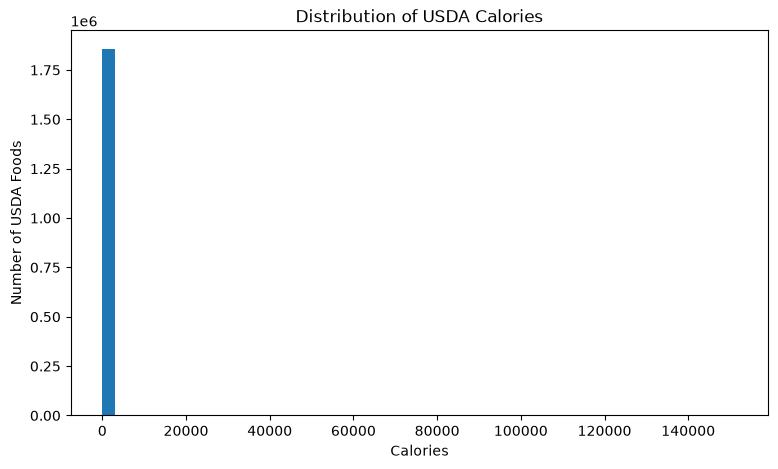

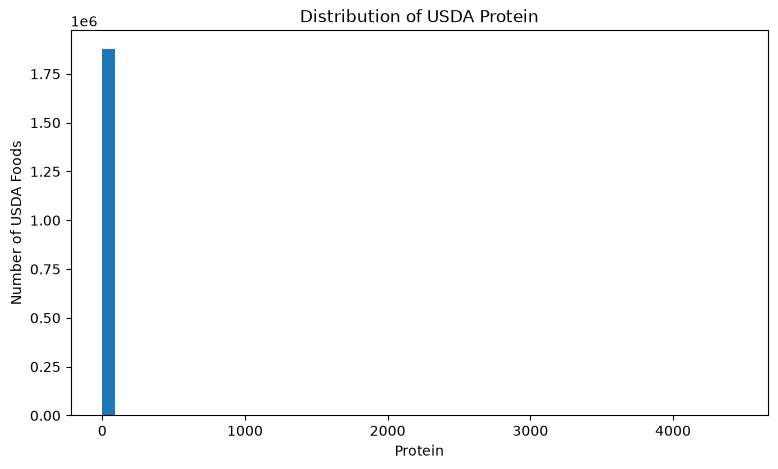

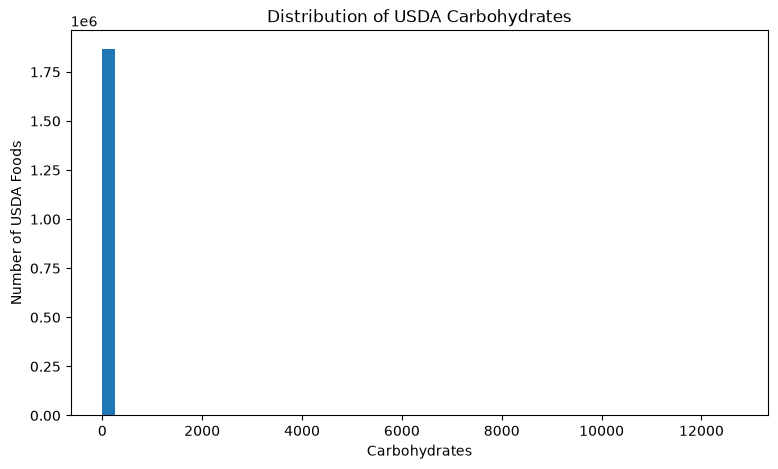

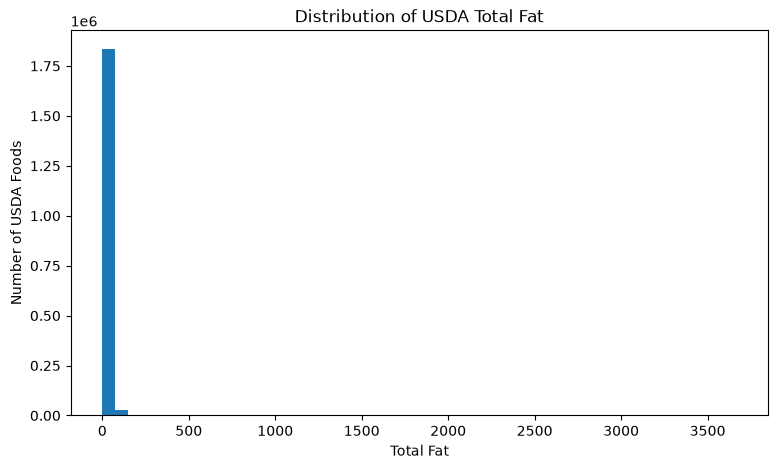

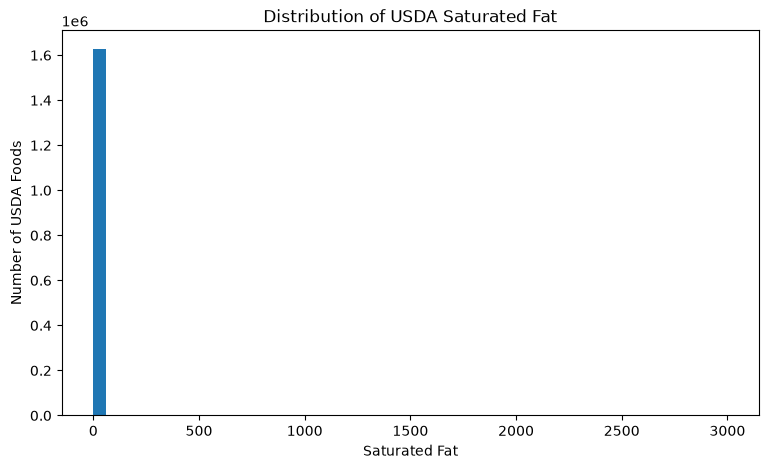

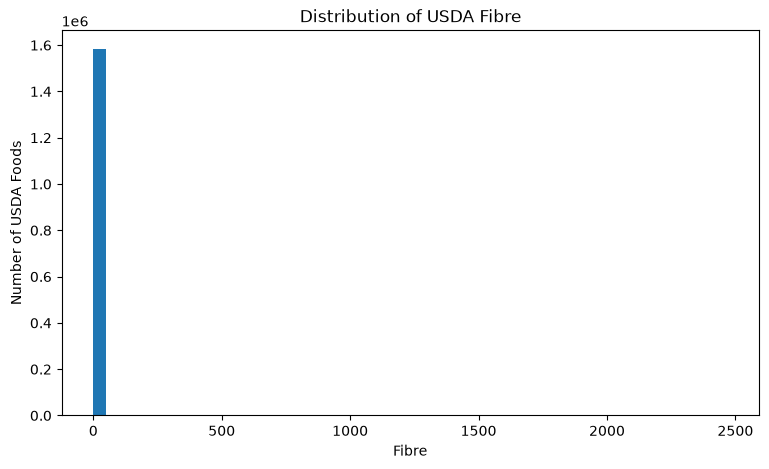

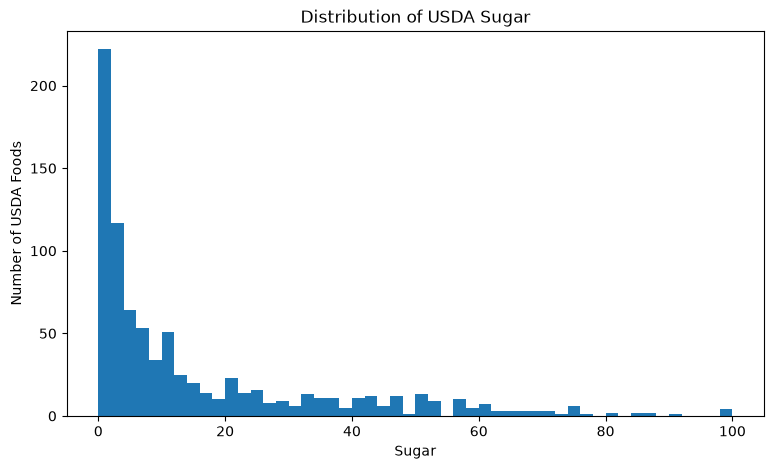

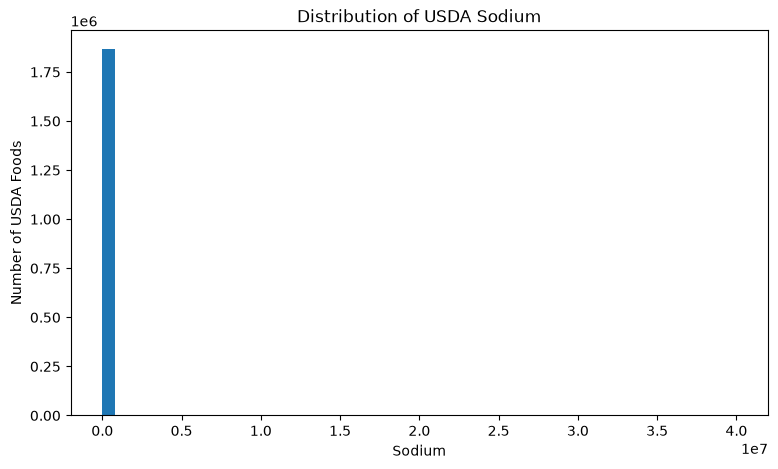

In [58]:
for column in nutrition_columns_usda:
    plt.figure(figsize=(9, 5))

    plt.hist(usda_nutrition_wide[column].dropna(), bins=50)

    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel("Number of USDA Foods")
    plt.title(f"Distribution of USDA {column.replace('_', ' ').title()}")

    plt.show()

In [59]:
usda_zero_summary = pd.DataFrame(
    {
        "zero_count": (usda_nutrition_wide[nutrition_columns_usda] == 0).sum(),
        "zero_percentage": ((usda_nutrition_wide[nutrition_columns_usda] == 0).mean() * 100),
    }
)

display(usda_zero_summary)

,zero_count,zero_percentage
calories,85331,4.498613
protein,456413,24.061895
carbohydrates,181420,9.564384
total_fat,537749,28.349893
saturated_fat,565386,29.806904
fibre,563690,29.717492
sugar,137,0.007223
sodium,261771,13.800453


In [60]:
print("=" * 70)
print("USDA FOUNDATION FOODS — NUTRITION EDA SUMMARY")
print("=" * 70)

print(f"\nTotal USDA food records:       {food['fdc_id'].nunique():,}")
print(f"Foods with nutrient records:   {food_nutrient['fdc_id'].nunique():,}")
print(f"Required nutrient rows:        {len(usda_nutrition):,}")
print(f"Final nutrition food records:  {len(usda_nutrition_wide):,}")

print("\nNutrition fields:")
for column in nutrition_columns_usda:
    print(f"- {column}")

print("\nFinal table shape:")
print(usda_nutrition_wide.shape)

print("=" * 70)

USDA FOUNDATION FOODS — NUTRITION EDA SUMMARY

Total USDA food records:       2,063,876
Foods with nutrient records:   1,949,042
Required nutrient rows:        12,558,136
Final nutrition food records:  1,896,829

Nutrition fields:
- calories
- protein
- carbohydrates
- total_fat
- saturated_fat
- fibre
- sugar
- sodium

Final table shape:
(1896829, 12)


In [61]:
display(nutrient_coverage)

,nutrient_id,name,unit_name,food_count,value_count,coverage_percentage
0,1003,Protein,G,1880268,1880391,91.103729
2,1005,"Carbohydrate, by difference",G,1870321,1870388,90.621772
6,1093,"Sodium, Na",MG,1868295,1868361,90.523607
1,1004,Total lipid (fat),G,1861569,1862357,90.197715
3,1008,Energy,KCAL,1858059,1858569,90.027647
7,1258,"Fatty acids, total saturated",G,1631059,1631062,79.028924
5,1079,"Fiber, total dietary",G,1585817,1586162,76.836835
4,1063,"Sugars, Total",G,846,846,0.040991


In [62]:
display(usda_missing)

,missing_count,missing_percentage
calories,38770,2.043938
protein,16561,0.873089
carbohydrates,26508,1.397490
total_fat,35260,1.858892
saturated_fat,265770,14.011279
fibre,311012,16.396417
sugar,1895983,99.955399
sodium,28534,1.504300


In [63]:
display(usda_nutrition_summary)

,count,mean,std,min,25%,50%,75%,max
calories,1858059.0,273.531602,357.963363,0.0,89.00,267.00,400.00,151515.00
protein,1880268.0,7.606925,14.309710,0.0,0.42,4.65,10.59,4444.44
carbohydrates,1870321.0,34.293764,49.136713,0.0,6.67,23.33,60.00,12700.00
total_fat,1861569.0,12.547500,22.341537,0.0,0.00,5.48,19.77,3666.67
saturated_fat,1631059.0,4.922813,10.903639,0.0,0.00,2.00,7.14,3000.00
fibre,1585817.0,2.915259,7.653689,0.0,0.00,1.50,3.60,2468.90
sugar,846.0,15.572643,20.026737,0.0,1.77,6.72,22.20,100.00
sodium,1868295.0,1514.621874,97556.105093,0.0,36.00,264.00,571.00,40000000.00


In [64]:
foundation_food = pd.read_csv(os.path.join(USDA_PATH, "foundation_food.csv"))

print("Shape:", foundation_food.shape)

print("\nColumns:")
print(foundation_food.columns.tolist())

display(foundation_food.head())

Shape: (395, 3)

Columns:
['fdc_id', 'NDB_number', 'footnote']


,fdc_id,NDB_number,footnote
0,321358,16158,NaN
1,321360,100147,NaN
2,321611,11056,NaN
3,323121,7022,NaN
4,323294,12563,Other phytosterols = 34.67 mg/100g


In [65]:
foundation_food.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   fdc_id      395 non-null    int64
 1   NDB_number  395 non-null    int64
 2   footnote    81 non-null     str  
dtypes: int64(2), str(1)
memory usage: 9.4 KB


In [66]:
display(
    pd.DataFrame(
        {
            "missing_count": foundation_food.isnull().sum(),
            "missing_percentage": foundation_food.isnull().mean() * 100,
        }
    )
)

,missing_count,missing_percentage
fdc_id,0,0.000000
NDB_number,0,0.000000
footnote,314,79.493671


In [67]:
print("Foundation Food records:", len(foundation_food))

print("Unique Foundation Food IDs:", foundation_food["fdc_id"].nunique())

Foundation Food records: 395
Unique Foundation Food IDs: 395


In [68]:
foundation_ids = set(foundation_food["fdc_id"])

food_ids = set(food["fdc_id"])

common_foundation_ids = foundation_ids.intersection(food_ids)

print("Foundation Food IDs:", len(foundation_ids))
print("Matching IDs in food:", len(common_foundation_ids))

print(
    f"Foundation Food ID coverage in food table: "
    f"{len(common_foundation_ids) / len(foundation_ids) * 100:.2f}%"
)

Foundation Food IDs: 395
Matching IDs in food: 314
Foundation Food ID coverage in food table: 79.49%


In [69]:
foundation_records = food[food["fdc_id"].isin(foundation_ids)].copy()

print("Foundation records in food table:", len(foundation_records))

display(foundation_records["data_type"].value_counts().to_frame("count"))

Foundation records in food table: 314


,count
data_type,
foundation_food,314


In [70]:
display(foundation_records[["fdc_id", "description", "data_type", "food_category_id"]].head(30))

,fdc_id,description,data_type,food_category_id
41375,321358,"Hummus, commercial",foundation_food,16
41377,321360,"Tomatoes, grape, raw",foundation_food,11
41628,321611,"Beans, snap, green, canned, regular pack, drained solids",foundation_food,11
43138,323121,"Frankfurter, beef, unheated",foundation_food,7
43311,323294,"Nuts, almonds, dry roasted, with salt added",foundation_food,12
43522,323505,"Kale, raw",foundation_food,11
43621,323604,"Egg, whole, raw, frozen, pasteurized",foundation_food,1
43714,323697,"Egg, white, raw, frozen, pasteurized",foundation_food,1
43810,323793,"Egg, white, dried",foundation_food,1
44334,324317,"Onion rings, breaded, par fried, frozen, prepared, heated in oven",foundation_food,11


In [71]:
foundation_food_nutrients = food_nutrient[food_nutrient["fdc_id"].isin(foundation_ids)].copy()

print("Foundation Food nutrient rows:", len(foundation_food_nutrients))

print("Foundation Foods with nutrient records:", foundation_food_nutrients["fdc_id"].nunique())

Foundation Food nutrient rows: 14070
Foundation Foods with nutrient records: 314


In [72]:
foundation_required_nutrients = foundation_food_nutrients[
    foundation_food_nutrients["nutrient_id"].isin(required_nutrient_ids.values())
].copy()

print("Rows containing required nutrients:", len(foundation_required_nutrients))

print("Foundation Foods represented:", foundation_required_nutrients["fdc_id"].nunique())

Rows containing required nutrients: 1646
Foundation Foods represented: 314


In [73]:
foundation_nutrient_coverage = (
    foundation_required_nutrients.merge(
        nutrient[["id", "name", "unit_name"]], left_on="nutrient_id", right_on="id", how="left"
    )
    .groupby(["nutrient_id", "name", "unit_name"])
    .agg(food_count=("fdc_id", "nunique"), value_count=("amount", "count"))
    .reset_index()
)

In [74]:
foundation_total_foods = len(foundation_ids)

foundation_nutrient_coverage["coverage_percentage"] = (
    foundation_nutrient_coverage["food_count"] / foundation_total_foods * 100
)

display(foundation_nutrient_coverage.sort_values("coverage_percentage", ascending=False))

,nutrient_id,name,unit_name,food_count,value_count,coverage_percentage
1,1004,Total lipid (fat),G,305,305,77.215190
0,1003,Protein,G,303,303,76.708861
2,1005,"Carbohydrate, by difference",G,284,284,71.898734
6,1093,"Sodium, Na",MG,284,284,71.898734
5,1079,"Fiber, total dietary",G,164,164,41.518987
4,1063,"Sugars, Total",G,111,111,28.101266
7,1258,"Fatty acids, total saturated",G,100,100,25.316456
3,1008,Energy,KCAL,95,95,24.050633


In [75]:
foundation_required_nutrients["nutrition_field"] = foundation_required_nutrients["nutrient_id"].map(
    nutrient_name_map
)

foundation_nutrition_wide = foundation_required_nutrients.pivot_table(
    index="fdc_id", columns="nutrition_field", values="amount", aggfunc="first"
).reset_index()

foundation_nutrition_wide.columns.name = None

print("Foundation nutrition table shape:", foundation_nutrition_wide.shape)

display(foundation_nutrition_wide.head())

Foundation nutrition table shape: (314, 9)


,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat
0,321358,229.0,14.90,5.4,7.35,2.22,438.0,0.34,17.10
1,321360,27.0,5.51,2.1,0.83,NaN,6.0,NaN,0.63
2,321611,21.0,4.11,NaN,1.04,NaN,282.0,1.29,0.39
3,323121,314.0,2.89,NaN,11.70,11.40,872.0,1.26,28.00
4,323294,620.0,16.20,11.0,20.40,4.56,256.0,4.17,57.80


In [76]:
foundation_nutrition_wide = foundation_nutrition_wide.merge(
    food[["fdc_id", "description", "data_type", "food_category_id"]], on="fdc_id", how="left"
)

display(foundation_nutrition_wide.head())

,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat,description,data_type,food_category_id
0,321358,229.0,14.90,5.4,7.35,2.22,438.0,0.34,17.10,"Hummus, commercial",foundation_food,16
1,321360,27.0,5.51,2.1,0.83,NaN,6.0,NaN,0.63,"Tomatoes, grape, raw",foundation_food,11
2,321611,21.0,4.11,NaN,1.04,NaN,282.0,1.29,0.39,"Beans, snap, green, canned, regular pack, drained solids",foundation_food,11
3,323121,314.0,2.89,NaN,11.70,11.40,872.0,1.26,28.00,"Frankfurter, beef, unheated",foundation_food,7
4,323294,620.0,16.20,11.0,20.40,4.56,256.0,4.17,57.80,"Nuts, almonds, dry roasted, with salt added",foundation_food,12


In [77]:
foundation_nutrition_wide = foundation_nutrition_wide[
    [
        "fdc_id",
        "description",
        "data_type",
        "food_category_id",
        "calories",
        "protein",
        "carbohydrates",
        "total_fat",
        "saturated_fat",
        "fibre",
        "sugar",
        "sodium",
    ]
]

display(foundation_nutrition_wide.head())

,fdc_id,description,data_type,food_category_id,calories,protein,carbohydrates,total_fat,saturated_fat,fibre,sugar,sodium
0,321358,"Hummus, commercial",foundation_food,16,229.0,7.35,14.90,17.10,2.22,5.4,0.34,438.0
1,321360,"Tomatoes, grape, raw",foundation_food,11,27.0,0.83,5.51,0.63,NaN,2.1,NaN,6.0
2,321611,"Beans, snap, green, canned, regular pack, drained solids",foundation_food,11,21.0,1.04,4.11,0.39,NaN,NaN,1.29,282.0
3,323121,"Frankfurter, beef, unheated",foundation_food,7,314.0,11.70,2.89,28.00,11.40,NaN,1.26,872.0
4,323294,"Nuts, almonds, dry roasted, with salt added",foundation_food,12,620.0,20.40,16.20,57.80,4.56,11.0,4.17,256.0


In [78]:
foundation_missing = pd.DataFrame(
    {
        "missing_count": (foundation_nutrition_wide[nutrition_columns_usda].isnull().sum()),
        "missing_percentage": (
            foundation_nutrition_wide[nutrition_columns_usda].isnull().mean() * 100
        ),
    }
)

display(foundation_missing)

,missing_count,missing_percentage
calories,219,69.745223
protein,11,3.503185
carbohydrates,30,9.554140
total_fat,9,2.866242
saturated_fat,214,68.152866
fibre,150,47.770701
sugar,203,64.649682
sodium,30,9.554140


In [79]:
foundation_nutrition_summary = foundation_nutrition_wide[nutrition_columns_usda].describe().T

display(foundation_nutrition_summary)

,count,mean,std,min,25%,50%,75%,max
calories,95.0,210.518421,174.979787,12.0,55.500000,156.000000,358.000000,833.00
protein,303.0,10.511897,10.584110,0.0,1.198125,7.380000,18.096075,79.90
carbohydrates,284.0,20.882787,26.179307,0.0,3.608738,8.555325,22.777820,99.60
total_fat,305.0,9.134142,16.769353,0.0,0.337500,1.450000,7.916000,99.10
saturated_fat,100.0,7.475362,10.478834,0.0,1.257500,3.668000,11.475000,82.50
fibre,164.0,4.316309,4.691514,0.0,1.800000,3.083000,4.724250,34.95
sugar,111.0,7.228815,11.226027,0.0,1.440000,4.500000,9.236000,99.80
sodium,284.0,299.307544,2312.822316,0.0,0.441250,17.260000,118.000000,38700.00


In [80]:
negative_values = {}

for column in nutrition_columns_usda:
    count = foundation_nutrition_wide[column].lt(0).sum()

    negative_values[column] = count

negative_summary = pd.DataFrame(
    negative_values.items(), columns=["nutrient", "negative_value_count"]
)

display(negative_summary)

,nutrient,negative_value_count
0,calories,0
1,protein,0
2,carbohydrates,0
3,total_fat,0
4,saturated_fat,0
5,fibre,0
6,sugar,0
7,sodium,0


In [81]:
display(
    foundation_nutrition_wide[foundation_nutrition_wide["carbohydrates"] < 0][
        ["fdc_id", "description", "carbohydrates"]
    ]
)

,fdc_id,description,carbohydrates


In [82]:
print("=" * 70)
print("USDA FOUNDATION FOODS — CORRECTED NUTRITION SUMMARY")
print("=" * 70)

print(f"\nFoundation Food records:       {len(foundation_ids):,}")

print(
    f"Foundation Foods with selected nutrients: {foundation_nutrition_wide['fdc_id'].nunique():,}"
)

print(f"Required nutrient observations: {len(foundation_required_nutrients):,}")

print(f"\nFinal nutrition table shape: {foundation_nutrition_wide.shape}")

print("\nNutrients:")
for column in nutrition_columns_usda:
    print("-", column)

print("=" * 70)

USDA FOUNDATION FOODS — CORRECTED NUTRITION SUMMARY

Foundation Food records:       395
Foundation Foods with selected nutrients: 314
Required nutrient observations: 1,646

Final nutrition table shape: (314, 12)

Nutrients:
- calories
- protein
- carbohydrates
- total_fat
- saturated_fat
- fibre
- sugar
- sodium


In [83]:
food_portion = pd.read_csv(os.path.join(USDA_PATH, "food_portion.csv"))

print("Shape:", food_portion.shape)

print("\nColumns:")
print(food_portion.columns.tolist())

Shape: (47173, 11)

Columns:
['id', 'fdc_id', 'seq_num', 'amount', 'measure_unit_id', 'portion_description', 'modifier', 'gram_weight', 'data_points', 'footnote', 'min_year_acquired']


In [84]:
food_portion.info()

<class 'pandas.DataFrame'>
RangeIndex: 47173 entries, 0 to 47172
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   47173 non-null  int64  
 1   fdc_id               47173 non-null  int64  
 2   seq_num              36718 non-null  float64
 3   amount               25127 non-null  float64
 4   measure_unit_id      47173 non-null  int64  
 5   portion_description  22047 non-null  str    
 6   modifier             45209 non-null  str    
 7   gram_weight          47173 non-null  float64
 8   data_points          14153 non-null  float64
 9   footnote             0 non-null      float64
 10  min_year_acquired    187 non-null    float64
dtypes: float64(6), int64(3), str(2)
memory usage: 4.0 MB


In [85]:
display(food_portion.head(20))

,id,fdc_id,seq_num,amount,measure_unit_id,portion_description,modifier,gram_weight,data_points,footnote,min_year_acquired
0,81549,167512,1.0,1.00,9999,NaN,serving,34.00,NaN,NaN,NaN
1,81550,167513,1.0,1.00,9999,NaN,serving 1 roll with icing,44.00,1.0,NaN,NaN
2,81551,167514,1.0,1.00,9999,NaN,serving,28.00,NaN,NaN,NaN
3,81552,167515,1.0,1.00,9999,NaN,serving,57.00,NaN,NaN,NaN
4,81553,167516,1.0,1.00,9999,NaN,"waffle, square",39.00,10.0,NaN,NaN
5,81554,167516,2.0,1.00,9999,NaN,"waffle, round",38.00,40.0,NaN,NaN
6,81555,167517,1.0,1.00,9999,NaN,oz,28.00,NaN,NaN,NaN
7,81556,167517,2.0,1.00,9999,NaN,"waffle round (4"" dia)",33.00,NaN,NaN,NaN
8,81557,167518,1.0,1.00,9999,NaN,waffle,35.00,NaN,NaN,NaN
9,81558,167519,1.0,1.00,9999,NaN,"waffle, round (4""dia)",32.00,NaN,NaN,NaN


In [86]:
portion_missing = pd.DataFrame(
    {
        "missing_count": food_portion.isnull().sum(),
        "missing_percentage": food_portion.isnull().mean() * 100,
    }
).sort_values("missing_percentage", ascending=False)

display(portion_missing)

,missing_count,missing_percentage
footnote,47173,100.000000
min_year_acquired,46986,99.603587
data_points,33020,69.997668
portion_description,25126,53.263519
amount,22046,46.734361
seq_num,10455,22.163102
modifier,1964,4.163399
id,0,0.000000
fdc_id,0,0.000000
measure_unit_id,0,0.000000


In [87]:
print("Unique foods with portion information:", food_portion["fdc_id"].nunique())

print("Total portion records:", len(food_portion))

Unique foods with portion information: 15245
Total portion records: 47173


In [88]:
foundation_portions = food_portion[food_portion["fdc_id"].isin(foundation_ids)].copy()

print("Foundation Foods with portion records:", foundation_portions["fdc_id"].nunique())

print("Foundation portion records:", len(foundation_portions))

Foundation Foods with portion records: 83
Foundation portion records: 123


In [89]:
display(foundation_portions.head(30))

,id,fdc_id,seq_num,amount,measure_unit_id,portion_description,modifier,gram_weight,data_points,footnote,min_year_acquired
14540,118804,321358,1.0,2.0,1001,NaN,NaN,33.9,21.0,NaN,2015.0
14544,118808,321360,1.0,5.0,1082,NaN,NaN,49.7,11.0,NaN,2016.0
14545,118809,321360,2.0,1.0,1000,NaN,NaN,152.0,11.0,NaN,2016.0
14595,118859,321611,1.0,1.0,1000,NaN,drained,129.0,24.0,NaN,2015.0
14723,118987,323121,1.0,1.0,1043,NaN,NaN,48.6,32.0,NaN,2015.0
14748,119012,323294,1.0,1.0,1000,NaN,whole,135.0,24.0,NaN,2001.0
14793,119057,323505,1.0,1.0,1000,NaN,"pieces of ~1""",20.6,9.0,NaN,2015.0
14796,119060,323604,1.0,1.0,1038,NaN,NaN,28.4,1.0,NaN,2017.0
14799,119063,323697,1.0,1.0,1038,NaN,NaN,28.4,1.0,NaN,2017.0
14805,119069,323793,1.0,1.0,1001,NaN,NaN,7.0,2.0,NaN,2017.0


In [90]:
[
    col
    for col in food_portion.columns
    if any(
        word in col.lower() for word in ["gram", "amount", "measure", "portion", "modifier", "unit"]
    )
]

['amount', 'measure_unit_id', 'portion_description', 'modifier', 'gram_weight']

In [91]:
print(food_portion.columns.tolist())

['id', 'fdc_id', 'seq_num', 'amount', 'measure_unit_id', 'portion_description', 'modifier', 'gram_weight', 'data_points', 'footnote', 'min_year_acquired']


In [92]:
display(
    food_portion[
        [
            col
            for col in food_portion.columns
            if col
            in [
                "fdc_id",
                "amount",
                "measure_unit_id",
                "portion_description",
                "gram_weight",
                "modifier",
            ]
        ]
    ].head(30)
)

,fdc_id,amount,measure_unit_id,portion_description,modifier,gram_weight
0,167512,1.00,9999,NaN,serving,34.00
1,167513,1.00,9999,NaN,serving 1 roll with icing,44.00
2,167514,1.00,9999,NaN,serving,28.00
3,167515,1.00,9999,NaN,serving,57.00
4,167516,1.00,9999,NaN,"waffle, square",39.00
5,167516,1.00,9999,NaN,"waffle, round",38.00
6,167517,1.00,9999,NaN,oz,28.00
7,167517,1.00,9999,NaN,"waffle round (4"" dia)",33.00
8,167518,1.00,9999,NaN,waffle,35.00
9,167519,1.00,9999,NaN,"waffle, round (4""dia)",32.00


In [93]:
portion_columns = [
    col
    for col in [
        "fdc_id",
        "amount",
        "measure_unit_id",
        "portion_description",
        "gram_weight",
        "modifier",
    ]
    if col in food_portion.columns
]

display(food_portion[portion_columns].head(30))

,fdc_id,amount,measure_unit_id,portion_description,gram_weight,modifier
0,167512,1.00,9999,NaN,34.00,serving
1,167513,1.00,9999,NaN,44.00,serving 1 roll with icing
2,167514,1.00,9999,NaN,28.00,serving
3,167515,1.00,9999,NaN,57.00,serving
4,167516,1.00,9999,NaN,39.00,"waffle, square"
5,167516,1.00,9999,NaN,38.00,"waffle, round"
6,167517,1.00,9999,NaN,28.00,oz
7,167517,1.00,9999,NaN,33.00,"waffle round (4"" dia)"
8,167518,1.00,9999,NaN,35.00,waffle
9,167519,1.00,9999,NaN,32.00,"waffle, round (4""dia)"


In [94]:
foundation_portion_coverage = pd.DataFrame(
    {
        "total_foundation_foods": [len(foundation_ids)],
        "foods_with_portions": [foundation_portions["fdc_id"].nunique()],
    }
)

foundation_portion_coverage["coverage_percentage"] = (
    foundation_portion_coverage["foods_with_portions"]
    / foundation_portion_coverage["total_foundation_foods"]
    * 100
)

display(foundation_portion_coverage)

,total_foundation_foods,foods_with_portions,coverage_percentage
0,395,83,21.012658


In [95]:
print("Foundation portion records:", len(foundation_portions))

print("Non-missing gram weights:", foundation_portions["gram_weight"].notna().sum())

print("Missing gram weights:", foundation_portions["gram_weight"].isna().sum())

print("Zero gram weights:", (foundation_portions["gram_weight"] == 0).sum())

Foundation portion records: 123
Non-missing gram weights: 123
Missing gram weights: 0
Zero gram weights: 0


In [96]:
print("Foundation portion records:", len(foundation_portions))

print("Non-missing gram weights:", foundation_portions["gram_weight"].notna().sum())

print("Missing gram weights:", foundation_portions["gram_weight"].isna().sum())

print("Zero gram weights:", (foundation_portions["gram_weight"] == 0).sum())

Foundation portion records: 123
Non-missing gram weights: 123
Missing gram weights: 0
Zero gram weights: 0


In [97]:
foundation_portions["gram_weight"].describe()

count    123.000000
mean     148.113821
std      156.508317
min        3.200000
25%       34.850000
50%      127.000000
75%      173.500000
max      814.000000
Name: gram_weight, dtype: float64

In [98]:
if "portion_description" in foundation_portions.columns:
    display(foundation_portions["portion_description"].value_counts().head(30).to_frame("count"))

,count
portion_description,
shredded,1


In [99]:
if "measure_unit_id" in foundation_portions.columns:
    print("Unique measurement units:", foundation_portions["measure_unit_id"].nunique())

    display(foundation_portions["measure_unit_id"].value_counts().head(30).to_frame("count"))

Unique measurement units: 30


,count
measure_unit_id,
1000,34
1071,11
1050,8
1001,7
1043,5
1038,5
1033,5
1028,4
1004,4


In [100]:
print("=" * 70)
print("USDA FOUNDATION FOODS — PORTION ANALYSIS")
print("=" * 70)

print(f"\nFoundation Foods: {len(foundation_ids):,}")

print(f"Foods with portion information: {foundation_portions['fdc_id'].nunique():,}")

print(f"Total portion records: {len(foundation_portions):,}")

if "gram_weight" in foundation_portions.columns:
    print(f"Non-missing gram weights: {foundation_portions['gram_weight'].notna().sum():,}")

print("=" * 70)

USDA FOUNDATION FOODS — PORTION ANALYSIS

Foundation Foods: 395
Foods with portion information: 83
Total portion records: 123
Non-missing gram weights: 123


In [101]:
print("=" * 70)
print("FOUNDATION FOOD PORTION DETAILS")
print("=" * 70)

print("\n1. Gram-weight statistics:")
display(foundation_portions["gram_weight"].describe())

print("\n2. Amount statistics:")
display(foundation_portions["amount"].describe())

print("\n3. Most common portion descriptions:")
display(
    foundation_portions["portion_description"].value_counts(dropna=False).head(30).to_frame("count")
)

print("\n4. Most common modifiers:")
display(foundation_portions["modifier"].value_counts(dropna=False).head(30).to_frame("count"))

print("=" * 70)

FOUNDATION FOOD PORTION DETAILS

1. Gram-weight statistics:


count    123.000000
mean     148.113821
std      156.508317
min        3.200000
25%       34.850000
50%      127.000000
75%      173.500000
max      814.000000
Name: gram_weight, dtype: float64


2. Amount statistics:


count    123.000000
mean       4.347154
std       17.632372
min        0.200000
25%        1.000000
50%        1.000000
75%        1.000000
max      100.000000
Name: amount, dtype: float64


3. Most common portion descriptions:


,count
portion_description,
NaN,122
shredded,1



4. Most common modifiers:


,count
modifier,
NaN,61
raw,4
sifted,3
cooked,3
medium,3
Edible,2
Peeled,2
drained,1
whole,1


In [102]:
measure_unit = pd.read_csv(os.path.join(USDA_PATH, "measure_unit.csv"))


In [103]:
print("Available USDA measurement units:")
display(measure_unit.head())

print("\nMeasurement-unit columns:")
print(measure_unit.columns.tolist())

Available USDA measurement units:


,id,name
0,1000,cup
1,1001,tablespoon
2,1002,teaspoon
3,1003,liter
4,1004,milliliter



Measurement-unit columns:
['id', 'name']


In [104]:
# ============================================================
# STAGE 6 — USDA FOOD COMPONENTS
# ============================================================

food_component = pd.read_csv(os.path.join(USDA_PATH, "food_component.csv"))

print("=" * 70)
print("USDA FOOD COMPONENTS")
print("=" * 70)

print("\nShape:", food_component.shape)

print("\nColumns:")
print(food_component.columns.tolist())

print("\nData types:")
display(food_component.dtypes)

print("\nFirst 10 rows:")
display(food_component.head(10))

USDA FOOD COMPONENTS

Shape: (3066, 8)

Columns:
['id', 'fdc_id', 'name', 'pct_weight', 'is_refuse', 'gram_weight', 'data_points', 'min_year_acquired']

Data types:


id                     int64
fdc_id                 int64
name                     str
pct_weight           float64
is_refuse                str
gram_weight          float64
data_points            int64
min_year_acquired    float64
dtype: object


First 10 rows:


,id,fdc_id,name,pct_weight,is_refuse,gram_weight,data_points,min_year_acquired
0,56885,320354,Bone and connective tissue,0.1,Y,1.3,2,NaN
1,56886,320354,External fat,1.0,Y,9.6,2,NaN
2,56887,320354,Handling loss,0.2,N,2.0,2,NaN
3,56888,320354,Seam fat,0.0,Y,0.0,2,NaN
4,56889,320354,Separable Lean,98.7,N,994.0,2,NaN
5,56890,320354,Total gram weight,NaN,N,1010.0,2,NaN
6,56891,320355,Bone and connective tissue,0.0,Y,0.0,6,NaN
7,56892,320355,External fat,1.0,Y,1.3,6,NaN
8,56893,320355,Handling loss,0.4,N,0.5,6,NaN
9,56894,320355,Seam fat,0.0,Y,0.0,6,NaN


In [105]:
print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

component_missing = food_component.isna().sum().to_frame("missing_count")

component_missing["missing_percentage"] = (
    component_missing["missing_count"] / len(food_component) * 100
)

display(component_missing.sort_values("missing_percentage", ascending=False))

MISSING VALUES


,missing_count,missing_percentage
min_year_acquired,2982,97.260274
pct_weight,2214,72.211350
id,0,0.000000
fdc_id,0,0.000000
name,0,0.000000
is_refuse,0,0.000000
gram_weight,0,0.000000
data_points,0,0.000000


In [106]:
print("=" * 70)
print("FOUNDATION FOOD COVERAGE")
print("=" * 70)

component_food_ids = set(food_component["fdc_id"].dropna())

foundation_component = food_component[food_component["fdc_id"].isin(foundation_ids)].copy()

print("Foundation foods with component records:", foundation_component["fdc_id"].nunique())

print("Foundation component records:", len(foundation_component))

print(
    "Foundation component coverage:",
    round(foundation_component["fdc_id"].nunique() / len(foundation_ids) * 100, 2),
    "%",
)

FOUNDATION FOOD COVERAGE
Foundation foods with component records: 7
Foundation component records: 45
Foundation component coverage: 1.77 %


In [107]:
print("\nFoundation component sample:")
display(foundation_component.head(30))


Foundation component sample:


,id,fdc_id,name,pct_weight,is_refuse,gram_weight,data_points,min_year_acquired
2214,59105,331897,Bone and cartilage,32.4,Y,33.7,60,2010.0
2215,59106,331897,Total gram weight,100.0,N,104.0,60,2010.0
2216,59107,331897,Separable Lean,57.9,N,60.2,60,2010.0
2217,59108,331897,Handling loss,1.5,N,1.5,60,2010.0
2218,59109,331897,Edible portion,57.9,N,60.2,60,2010.0
2219,59110,331897,Skin and separable fat,8.7,Y,9.0,60,2010.0
3027,59918,746758,Connective tissue,0.3,Y,1.4,24,2011.0
3028,59919,746758,External fat,0.5,Y,2.1,24,2011.0
3029,59920,746758,Handling loss,0.2,N,0.8,24,2011.0
3030,59921,746758,Seam fat,0.5,Y,2.5,24,2011.0
